# Exercise: Which Pre-processing Steps Help? Arabic Tweet Sentiment
### Uses **only** techniques from the self-study notebook *Text Classification + Raw Text Processing*

## The scenario
Tweets are noisy: links, mentions, hashtags, repeated letters (*رااائع*), numbers, punctuation. Your job is to build a **positive / negative** classifier for Arabic tweets and, above all, to **measure the effect of every pre-processing step separately**, then combine the useful ones. This is exactly the "experiment cycle" of the notebook.

**Dataset:** [Arabic Sentiment Twitter Corpus](https://www.kaggle.com/datasets/mksaad/arabic-sentiment-twitter-corpus) (tab-separated files `train_...positive...tsv`, `train_...negative...tsv`, plus test files). Download it, unzip, and put the `.tsv` files next to this notebook (Colab: 📁 Files panel).

## The rules
1. **No new code ideas.** Every function you need is in the self-study notebook. Open it side by side and **copy → paste → adapt**.
2. **No stemming.** The notebook's `PorterStemmer` only knows English suffixes; it does nothing useful for Arabic, so we never use it.
3. Split **first**, explore **after**. Never fit anything on the test set.
4. Every part ends with a ✅ self-check cell. Run it before moving on.

## 🧰 Toolbox: what to copy from the self-study notebook
| You need | Where in the self-study notebook |
|---|---|
| `train_test_split` | Section 2 |
| Baseline, length histograms | 2.1, 2.2 |
| `WhitespaceTokenizer`, `TweetTokenizer` | 3.1 |
| `dropna`, `drop_duplicates` | 3.3 |
| Remove URLs / `#` / mentions | 3.3 (`re.sub(r'^RT(\s)+\|https?\S+\|#\|@\S+', ...)`) |
| `[^\w\s]` (remove every symbol) | Section 7 solution, `clean_message` |
| Repeated letters `([a-z])\1{2,}` → `\1` | 3.1 practice exercise, hint 2 |
| `replace_numbers` | 5.5 |
| `stopwords`, `remove_stopwords` | 5.3 |
| `negation_words`, `replace_negations` | 5.4 |
| `fit_and_score` | 4.2 |
| `CountVectorizer` `fit_transform` / `transform` | 5.2 (`cv`), Section 7 Step 3 |
| `tfidf` | 6 |
| Results bar chart | 6.1 |

## Part 0 · Setup and data *(given)*

In [1]:
import re, os, glob, csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.tokenize import TweetTokenizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import accuracy_score

for package in ['stopwords', 'punkt', 'punkt_tab']:
    nltk.download(package, quiet=True)
from nltk.corpus import stopwords

results = {}      # collect every experiment here (same idea as the notebook)

The corpus ships as one file per class and per split. We load **only the training files** (positive + negative) and do our *own* split with `train_test_split`, as in the notebook. The official test files stay untouched for a final check in the stretch tasks. We take a random sample of **20,000** tweets so that every experiment runs in seconds.

> ℹ️ The tweets were collected with positive/negative **emojis** and then labelled by them, so the labels are *distant* (noisy) labels, not human judgements. Keep this in mind when you look at the errors.

In [2]:
files = [f for f in glob.glob("**/*.tsv", recursive=True) if "train" in os.path.basename(f).lower()]
assert files, "No train .tsv files found. Put the corpus files next to this notebook."

parts = []
for f in files:
    label = 1 if "pos" in os.path.basename(f).lower() else 0          # 1 = positive, 0 = negative
    tmp = pd.read_csv(f, sep="\t", header=None, quoting=csv.QUOTE_NONE, on_bad_lines="skip", dtype=str)
    parts.append(pd.DataFrame({"text": tmp.iloc[:, -1], "label": label}))
    print(f"{os.path.basename(f)}: {len(tmp)} rows -> label {label}")

data = pd.concat(parts, ignore_index=True)
data = data.sample(n=20000, random_state=40).reset_index(drop=True)
print(data["label"].value_counts())
data.head(10)

train_Arabic_tweets_negative_20190413.tsv: 23121 rows -> label 0
train_Arabic_tweets_positive_20190413.tsv: 23879 rows -> label 1
label
1    10196
0     9804
Name: count, dtype: int64


,text,label
0,قال لها :إنتي نزلتي من عيني 😔 ! قالت :تصدق 😟✋ ...,0
1,ماعندي خبر 💔 بس قد صارتلي نفس المشكلة وانا موب...,0
2,أبوك يا حنين كان حنين هو زاتو الله يرحمو و يغف...,1
3,مستواك تحسن بعد ما لعبت معي 🌚,0
4,✔️ الحلقة التاسعة عشر من السيرة النبوية في تغر...,0
5,صباح الأمل حينما ندرك أن كل شيء بيد الله💕 صباح...,1
6,اقصد جونقكوك طبعا 🌚,0
7,صباح الخيير 😊,1
8,يانيشيمورا اشبيك 😔,0
9,"""تلاتين سنة بترقص .. الليلة رقصتنا"" أنا ببكي 😭...",0


## Part 1 · Split, duplicates, leakage
**1a.** Split `data["text"]` / `data["label"]` (as lists) with `test_size=0.2`, `random_state=40` into `X_train, X_test, y_train, y_test`, then build `train_df` and `test_df` (columns `text`, `label`).

**1b.** Remove empty rows and duplicates in each DataFrame (Section 3.3), then re-create the lists `train_texts`, `test_texts`, `y_train`, `y_test` from the DataFrames (first cell of Section 4, but using the **raw** `text` column: we have not cleaned anything yet).

**1c.** Tweets are often retweets. The given line counts how many test tweets also appear in the training set (`overlap`).

> 🤔 **Think:** Section 3.3 asked the same question. Is `overlap > 0` a problem for the evaluation? Which direction does it push the accuracy?

In [8]:
# TODO 1a
# data.drop_duplicates(inplace=True)
X = data["text"].tolist()
y = data["label"].tolist()

X_train , X_test , y_train , y_test = train_test_split(X,y, test_size=0.2, random_state=40)
train_df , test_df = pd.DataFrame({'text':X_train , 'label' :y_train}), pd.DataFrame({'text':X_test , 'label' :y_test})
print(len(X_test), len(y_test))
# TODO 1b
train_texts = train_df['text'].tolist()
test_texts = test_df['text'].tolist()

# 1c (given): how many test tweets also appear in train?
overlap = len(set(train_texts or []) & set(test_texts or []))
print(len(train_df), len(test_df), "overlap:", overlap)

4000 4000
16000 4000 overlap: 790


In [9]:
# ✅ Self-check, Part 1
if train_texts is None or overlap is None:
    print("⚠️ Part 1 not done yet.")
else:
    ok_len = len(train_texts) == len(y_train) and len(test_texts) == len(y_test)
    ok_size = 8000 < len(train_texts) <= 16000 and 2000 < len(test_texts) <= 4000
    print("✅" if ok_len else "❌", "texts and labels have the same length")
    print("✅" if ok_size else "❌", "sizes plausible (≤16000 / ≤4000 after removing duplicates)")

✅ texts and labels have the same length
✅ sizes plausible (≤16000 / ≤4000 after removing duplicates)


## Part 2 · Explore the **training** data
**2a.** Majority-class `baseline` (Section 2.1).
**2b.** Histograms of words per tweet for the two classes (Section 2.2).
**2c.** 👀 Run the given cell and list the kinds of noise you see. Which of them could be useful for sentiment, and which are just noise?

> 🤔 **Think:** why do we skip the word cloud of Section 2.3 for Arabic? (See the notebook's own Think about the word `t`.)

In [20]:
# TODO 2a
baseline =  pd.Series(y_train).value_counts(normalize=True).max()
print("Majority-class baseline:",baseline)

Majority-class baseline: 0.509375


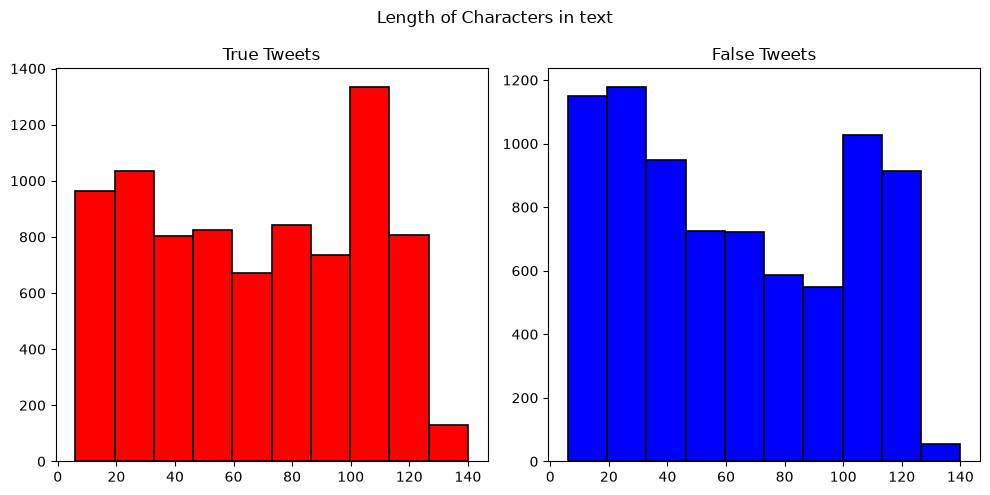

In [21]:
fig,(ax1,ax2) = plt.subplots(1, 2, figsize=(10,5))
char_len_dis = train_df[train_df['label'] == 1]['text'].str.len()
ax1.hist(char_len_dis,color='red',edgecolor='black', linewidth=1.2)
ax1.set_title('True Tweets')

char_len_ndis = train_df[train_df['label'] == 0]['text'].str.len()
ax2.hist(char_len_ndis,color='blue',edgecolor='black', linewidth=1.2)
ax2.set_title('False Tweets')

plt.suptitle("Length of Characters in text")
plt.tight_layout()
plt.show()

In [22]:
for t in train_df['text'].sample(8, random_state=5):
    print("-", t)

- مبروك على تعين أستاذ جو معلوف سفيرا لحماية الأحداث في لبنان الف مبروك 🇱🇧 نفتخر فيك ❤
- ايه كلها لحد الثانويه العامه 😍 بس بالجامعه من العشر الاواخر 🌚بس نجحت الحمدلله 🙄
- والله هذي اهون :(
- صباح النصر ✌ يارب وفق نصرنا 💛 💙
- رحمة الله تغشاهم اليمن 🇾🇪حزينه لما جرى لهم 😭 انا لله وانا اليه راجعون حسبنا الله ونعم الوكيل 💔
- هو ما بيقدر بس السعوديه رح تخليه يقدر بالغصب 😓
- بوسوا العيون اللي تحبونها :(
- اللهم نسألك السلامة في ديننا وأبداننا ، والمغفرة لآبائنا وأمهاتنا ، والهداية لابنائنا والرحمة…


In [23]:
# ✅ Self-check, Part 2
print("✅ baseline ok" if baseline is not None and 0.5 <= baseline <= 1 else "⚠️ Part 2a not done / not in [0.5, 1]")

✅ baseline ok


## Part 3 · Write the pre-processing **steps**
Each step is **one small function** `text -> text`, collected in the dictionary `steps`. Every one is a line or two from the notebook.

| Step name | What it does | Source in the notebook |
|---|---|---|
| `'lower'` | lowercase (matters for Latin words in tweets) | 3.3 |
| `'urls'` | delete links | 3.3 regex `https?\S+` |
| `'mentions'` | delete `@user` | 3.3 regex `@\S+` |
| `'hashtag_split'` | replace `#` **and** `_` by a space, so `#الحياة_جميلة` becomes two words | **given** |
| `'elongation'` | shrink a letter repeated 3+ times to one (`رااائع` → `رائع`) | **given** (the regex is the idea of the 3.1 practice exercise, hint 2) |
| `'punct_all'` | delete **every** character that is not a letter, digit, `_` or space (also removes emojis) | Section 7 `clean_message`: `[^\w\s]` |
| `'numbers_tag'` | digits → `_NUM` | 5.5 `replace_numbers` |
| `'stopwords'` | delete Arabic stop words | 5.3 with `stopwords.words('arabic')` |
| `'negation_stop'` | replace negations by `_NEG`, **then** delete stop words | 5.4 with the Arabic list `['لا','لم','لن','ليس','ليست','ما','غير','بدون','مش']` |

First, a quick look at tokenizers on one real tweet (3.1): compare how `WhitespaceTokenizer` and `TweetTokenizer` treat the hashtag, the mention and the punctuation.

In [ ]:
t = next(x for x in train_texts if '#' in x or '@' in x)
print(t)
print(nltk.tokenize.WhitespaceTokenizer().tokenize(t))
print(TweetTokenizer().tokenize(t))

In [36]:
# TODO 3: complete the steps (one function each). Paste helpers from the notebook where needed.
stop_words = stop_words = set(stopwords.words('arabic'))                # TODO: set(stopwords.words('arabic'))
negation_words = ['لا','لم','لن','ليس','ليست','ما','غير','بدون','مش']            # TODO: the Arabic negation list above

steps = {
    'lower':         lambda t: t.lower(),        # TODO
    'urls':          lambda t: re.sub(r"https?\S+",'',t),        # TODO
    'mentions':      lambda t: re.sub(r"@\S+",'',t),        # TODO
    'hashtag_split': lambda t: re.sub(r'[#_]', ' ', t),            # given
    'elongation':    lambda t: re.sub(r'(\w)\1{2,}', r'\1', t),      # given
    'punct_all':     lambda t: re.sub(r"[^\w\s_]+" , " ",t),        # TODO
    'numbers_tag':   lambda t: re.sub(r"\d+" , " _NUM ",t),        # TODO
    'stopwords':     lambda t: " ".join(w for w in t.split() if w not in stop_words),        # TODO
    'negation_stop': lambda t: " ".join(w for w in (" ".join('_NEG' if w in negation_words else w for w in t.split())).split() if w not in stop_words),        # TODO
}

In [37]:
# ✅ Self-check, Part 3: each step is tested on the same probe tweet
probe = "@user1 وااااو رائع جدا!!! #الحياة_جميلة http://t.co/x 100 مرة، ليس سيئ؟ Hello"
tests = {
    'lower':         lambda o: 'hello' in o,
    'urls':          lambda o: 'http' not in o,
    'mentions':      lambda o: '@user1' not in o,
    'hashtag_split': lambda o: 'الحياة جميلة' in o,
    'elongation':    lambda o: 'ااا' not in o,
    'punct_all':     lambda o: '!' not in o and '،' not in o and '؟' not in o,
    'numbers_tag':   lambda o: '_NUM' in o,
    'stopwords':     lambda o: 0 < len(o) <= len(probe),
    'negation_stop': lambda o: '_NEG' in o,
}
for name, check in tests.items():
    try:
        ok = check(steps[name](probe))
    except Exception:
        ok = False
    print("✅" if ok else "❌", name)

✅ lower
✅ urls
✅ mentions
✅ hashtag_split
✅ elongation
✅ punct_all
✅ numbers_tag
✅ stopwords
✅ negation_stop


> 🤔 **Think (2 sentences):** Why do we **not** include a stemming step? What would you need instead for Arabic that the notebook does not provide?

## Part 4 · Experiment A: test each step **alone**
The question: *does this one step change the accuracy, compared with doing no cleaning at all?* Every experiment is the same recipe, so you write it **once** as a function `evaluate(step_names, name)` and call it many times.

**4a.** Paste `fit_and_score` (Section 4.2).

**4b.** Complete `evaluate`. Cleaning is **given** (`apply_steps`). You write the three **fitting** lines, the recipe of Section 5.2:
1. learn the vocabulary on the **training** texts and convert them (`X_tr`) with `CountVectorizer`;
2. convert the **test** texts with the **same** vocabulary (`X_te`);
3. train and score with `fit_and_score` (`acc`).

**4c.** Run the no-cleaning baseline `evaluate([], 'raw')`, then a loop over all steps, **one at a time**: `evaluate([name], name)`.

**4d.** Run the given table cell. It shows each step's accuracy, its difference from `raw`, and what that difference means **in tweets**.

In [38]:
# TODO 4a: paste fit_and_score here
def fit_and_score(X_tr, y_tr, X_te, y_te):
    clf = LogisticRegression(random_state=40)
    clf.fit(X_tr, y_tr)                  # learn from the TRAINING data only
    y_predicted = clf.predict(X_te)      # predict the unseen TEST data
    return accuracy_score(y_te, y_predicted), clf


# TODO 4b: complete evaluate
def apply_steps(texts, step_names):          # given: applies the steps in order
    out = []
    for t in texts:
        for s in step_names:
            t = steps[s](t)
        out.append(" ".join(t.split()))
    return out

def evaluate(step_names, name):
    train_clean = apply_steps(train_texts, step_names)
    test_clean = apply_steps(test_texts, step_names)
    vec = CountVectorizer(ngram_range=(1, 2), min_df=1)       # <-- edit me
    # TODO 4b-1: vocabulary from TRAIN -> X_tr
    X_tr = vec.fit_transform(train_clean)
    # TODO 4b-2: same vocabulary on TEST -> X_te
    X_te = vec.transform(test_clean)
    # TODO 4b-3: acc, _ = fit_and_score(...)
    acc , _ = fit_and_score(X_tr, y_train,X_te,y_test)
    results[name] = acc
    print(f"{name:15s} {X_tr.shape[1]:6d} features  accuracy = {acc:.4f}")
    return acc

In [39]:
# ✅ Self-check for evaluate: the raw model must beat the baseline
try:
    acc_raw = evaluate([], 'raw')
    print("✅ evaluate works" if acc_raw > baseline else "🤔 raw does not beat the baseline: check Part 1 and your fitting lines")
except Exception as e:
    print("❌ evaluate is not complete yet:", type(e).__name__, e)

raw             132639 features  accuracy = 0.7678
✅ evaluate works


In [40]:
# TODO 4c: loop over all steps, one at a time
evaluate([],'raw')
for k in steps.keys():
  evaluate([k] , k)

raw             132639 features  accuracy = 0.7678
lower           132639 features  accuracy = 0.7678
urls            132639 features  accuracy = 0.7678
mentions        132639 features  accuracy = 0.7678
hashtag_split   133204 features  accuracy = 0.7695
elongation      132639 features  accuracy = 0.7678
punct_all       132639 features  accuracy = 0.7678
numbers_tag     132495 features  accuracy = 0.7678
stopwords       118818 features  accuracy = 0.7625
negation_stop   120031 features  accuracy = 0.7620


In [43]:
# 4d (given): every experiment compared with 'raw'
table = pd.DataFrame({'accuracy': pd.Series(results)})
table['diff vs raw'] = table['accuracy'] - results['raw']
table['≈ tweets'] = (table['diff vs raw'] * len(y_test)).round().astype(int)
table.sort_values('accuracy', ascending=False).round(4)

,accuracy,diff vs raw,≈ tweets
cum 7 +numbers_tag,0.7702,0.0025,10
hashtag_split,0.7695,0.0017,7
cum 6 +punct_all,0.7695,0.0017,7
cum 8 +negation_stop,0.7695,0.0017,7
cum 4 +hashtag_split,0.7695,0.0017,7
cum 5 +elongation,0.7695,0.0017,7
lower,0.7678,0.0000,0
raw,0.7678,0.0000,0
mentions,0.7678,0.0000,0
urls,0.7678,0.0000,0


**Answer in 1 line each** (a difference below **0.005 ≈ 17 tweets** is within the noise: do not report it as a win):

| Question | Your answer |
|---|---|
| Which 2-3 steps helped most? | NO ONE HELPED |
| Which steps did nothing (within ±0.005)? | ALL OF THEM except negation stop|
| Did any step **hurt**? Why might it? |negation stop, idk|
| `stopwords` vs `negation_stop`: which is better, and what does that say about negation? | |
| `stopwords` alone on *raw* text removes few words. Why? (Hint: punctuation stuck to words, e.g. `في،`.) | |

## Part 5 · Experiment B: add the steps one by one (cumulative)
Single steps can interact (stop words only work after punctuation is gone). So now we build a pipeline **step by step**: each experiment applies all previous steps **plus one more**.

**5a.** Run the given loop. It uses this order: `order = ['lower', 'urls', 'mentions', 'hashtag_split', 'elongation', 'punct_all', 'numbers_tag', 'negation_stop']`.

**5b.** Run the given table: accuracy after each added step, and the change caused by **that** step (in tweets).

**5c.** Decide your **`final_steps`**: the subset/order you trust, based on Experiments A **and** B (steps that did nothing or hurt can go). Then evaluate it with `evaluate(final_steps, 'final pipeline')`.

> 🤔 **Think:** Is your best cumulative result better than the best single step of Part 4? Is the *last* step added always the best one to keep?

In [42]:
# 5a (given): add the steps one by one
order = ['lower', 'urls', 'mentions', 'hashtag_split', 'elongation', 'punct_all', 'numbers_tag', 'negation_stop']

cum_names = []
for i in range(1, len(order) + 1):
    name = 'cum ' + str(i) + ' +' + order[i-1]
    cum_names.append(name)
    evaluate(order[:i], name)

cum 1 +lower    132639 features  accuracy = 0.7678
cum 2 +urls     132639 features  accuracy = 0.7678
cum 3 +mentions 132639 features  accuracy = 0.7678
cum 4 +hashtag_split 133204 features  accuracy = 0.7695
cum 5 +elongation 133204 features  accuracy = 0.7695
cum 6 +punct_all 133204 features  accuracy = 0.7695
cum 7 +numbers_tag 133017 features  accuracy = 0.7702
cum 8 +negation_stop 119497 features  accuracy = 0.7695


In [49]:
# TODO 5c: write the list of steps you decide to keep, then evaluate it
final_steps =  ['lower', 'urls', 'mentions', 'hashtag_split', 'elongation', 'punct_all', 'numbers_tag']
evaluate (final_steps , 'final pipeline')

final pipeline  133017 features  accuracy = 0.7702


0.77025

In [50]:
# 5b (given): accuracy after each added step, and the effect of that step alone
cum = pd.DataFrame({'accuracy': pd.Series({n: results[n] for n in cum_names})})
cum['change (tweets)'] = (cum['accuracy'].diff().fillna(cum['accuracy'] - results['raw']) * len(y_test)).round().astype(int)
cum.round(4)

,accuracy,change (tweets)
cum 1 +lower,0.7678,0
cum 2 +urls,0.7678,0
cum 3 +mentions,0.7678,0
cum 4 +hashtag_split,0.7695,7
cum 5 +elongation,0.7695,0
cum 6 +punct_all,0.7695,0
cum 7 +numbers_tag,0.7702,3
cum 8 +negation_stop,0.7695,-3


In [51]:
# ✅ Self-check, Part 5
if final_steps is None:
    print("⚠️ 5c not done yet.")
else:
    bad = [s for s in final_steps if s not in steps]
    print(f"❌ unknown steps: {bad}" if bad else f"✅ final_steps valid: {final_steps}")
    print("✅ 'final pipeline' stored" if 'final pipeline' in results else "⚠️ run evaluate(final_steps, 'final pipeline')")

✅ final_steps valid: ['lower', 'urls', 'mentions', 'hashtag_split', 'elongation', 'punct_all', 'numbers_tag']
✅ 'final pipeline' stored


## Part 6 · TF-IDF, error analysis, conclusions
**6a.** Cleaning with your `final_steps` is given. Paste the `tfidf` function (Section 6), then fit it on the cleaned train texts, transform the cleaned test texts, and run `fit_and_score`. Keep the objects `tfidf_vectorizer`, `X_test_tfidf`, `clf_tfidf`.

**6b.** The given cell prints 5 misclassified test tweets (original text) with their true label.

**6c. Write 5-6 sentences below:**
1. Rank the pre-processing steps by usefulness, and state which differences you do **not** trust (and why: size of the test set).
2. Did TF-IDF + bigrams help compared to the best Bag of Words?
3. Name **two reasons** for your 5 errors (sarcasm, dialect, negation, labels that come from emojis, a tweet with no sentiment words...).

In [52]:
# given: clean with your final pipeline
final_train = apply_steps(train_texts, final_steps)
final_test = apply_steps(test_texts, final_steps)

# TODO 6a: paste tfidf() from Section 6, then:
def tfidf(data, min_df=10, max_df=0.75):
    tfidf_vectorizer = TfidfVectorizer(min_df=min_df, max_df=max_df, ngram_range=(1, 2))
    train = tfidf_vectorizer.fit_transform(data)
    return train, tfidf_vectorizer
X_train_tfidf, tfidf_vectorizer = tfidf(final_train)
X_test_tfidf = tfidf_vectorizer.transform(final_test)
acc_tfidf, clf_tfidf = fit_and_score(X_train_tfidf, y_train, X_test_tfidf,y_test)
results['final + TF-IDF'] = acc_tfidf

In [53]:
# 6b (given): five misclassified test tweets
y_pred = clf_tfidf.predict(X_test_tfidf)
wrong = [(t, true) for t, true, pred in zip(test_texts, y_test, y_pred) if true != pred]
print("errors:", len(wrong), "of", len(y_test))
for t, true in wrong[:5]:
    print(f"true={true} | {t}\n")

errors: 1171 of 4000
true=1 | خلاص انتم حبيبات فكوني من شركم 😂

true=1 | ولو بشرب مش هعرف 😂

true=0 | #قلبي .. وما أجمل أن ترسم أبجديات روحك #بالهوى لسعة يا تقتلك يا تصحيك خذه من باب التجربة وتذكرها ..! بس انتبه لا…

true=1 | والله شكلها مبيوعه 😊

true=0 | قاعده اقنع مخي ترى 😭



In [54]:
# ✅ Self-check, Part 6
print("✅ TF-IDF result stored" if 'final + TF-IDF' in results else "⚠️ Part 6a not done yet.")

✅ TF-IDF result stored


✍️ **Your answer (6c):** *(double-click to edit)*

## ⭐ Stretch (optional)
1. **Is the ranking stable?** Change `random_state` in the split (40 → 1 → 2), re-run Parts 1-5 and compare the rankings. Which conclusions survive?
2. **Which words matter?** Run the given cell: the words with the most negative / most positive weights in `clf_tfidf` (Section 7 challenge). Do you see emoji-related words or dialect words?
3. **Use the model:** the same cell defines `predict_tweet`, which applies `final_steps` → `tfidf_vectorizer` → `clf_tfidf` (like `predict_message` in Section 7). Try it on tweets of your own, one with a negation.

In [55]:
# given
words = tfidf_vectorizer.get_feature_names_out()
order_w = np.argsort(clf_tfidf.coef_[0])
print("Most NEGATIVE:", [words[i] for i in order_w[:10]])
print("Most POSITIVE:", [words[i] for i in order_w[-10:][::-1]])

def predict_tweet(text):
    cleaned = apply_steps([text], final_steps)
    vec = tfidf_vectorizer.transform(cleaned)
    return "positive" if clf_tfidf.predict(vec)[0] == 1 else "negative"

for r in ["الجو جميل اليوم والحياة حلوة", "ما عجبني الفيلم ابدا", "خدمة سيئة جدا"]:
    print(predict_tweet(r), "<-", r)

Most NEGATIVE: ['ليش', 'أين', 'دون', 'الجنوب', 'خسارة', 'فهناك', 'ضاقت', 'جماعة', 'الله يستر', 'فاضي']
Most POSITIVE: ['السحب', 'محمد', 'اللهم', 'مبروك', 'الورد', 'صباحك', 'يسعدك', 'نجم', 'الهلال', 'السماء']
positive <- الجو جميل اليوم والحياة حلوة
negative <- ما عجبني الفيلم ابدا
positive <- خدمة سيئة جدا
